In [25]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

In [26]:
G = nx.karate_club_graph()
print(G.number_of_nodes(), G.number_of_edges())

34 78


In [27]:
pos = nx.spring_layout(G, seed =42)

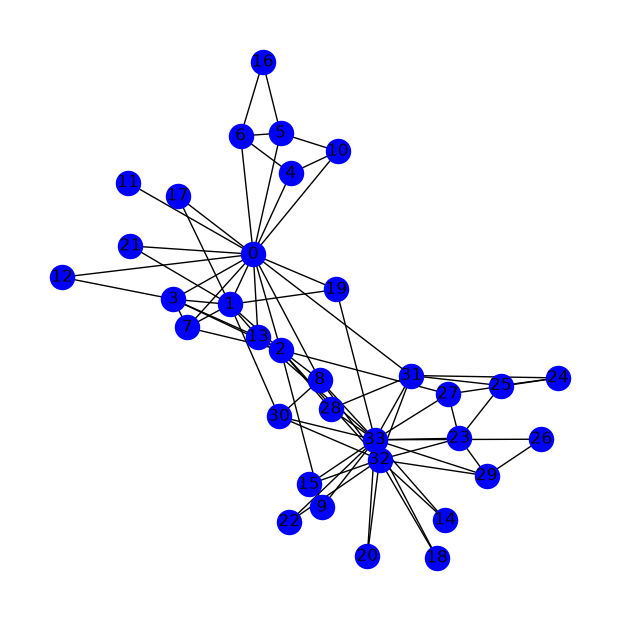

In [28]:
plt.figure(figsize=(6,6))
nx.draw(G, pos, with_labels=True, node_color="blue")
plt.show()

In [29]:
A = nx.to_numpy_array(G)
k = A.sum(axis=1)
m = G.number_of_edges()
B = A - np.outer(k,k)/(2*m)

In [30]:
def split_group(nodes):
    B_nodes = B[np.ix_(nodes,nodes)]
    values, vectors = np.linalg.eigh(B_nodes)
    top_value = values[-1]
    top_vector = vectors[:, -1]

    if top_value<=1e-8:
        return None

    group1=[nodes[i] for i in range(len(nodes)) if top_vector[i]>0]
    group2=[nodes[i] for i  in range(len(nodes)) if top_vector[i]<=0]

    if len(group1)==0 or len(group2)==0:
        return None
    
    s=np.where(top_vector> 0, 1, -1)
    gain = s @ B_nodes @ s
    if gain<1e-8:
        return None

    return group1, group2

In [31]:
all_nodes = list(range(34))
result = split_group(all_nodes)
print(result)

([8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33], [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21])


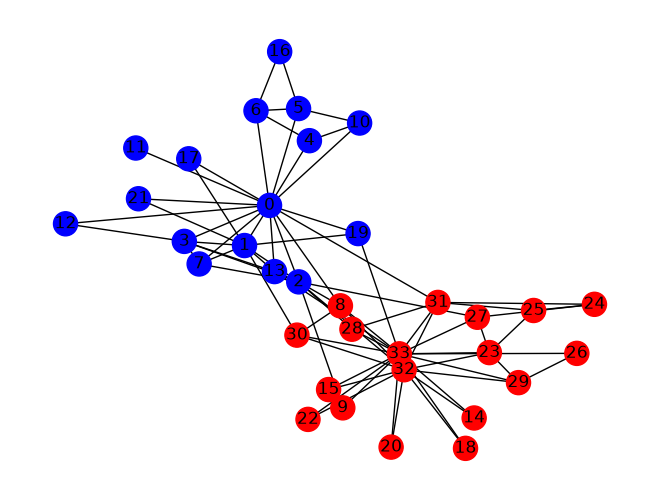

In [32]:
values, vectors = np.linalg.eigh(B)
top_vector = vectors[:, -1]

colors = ["red" if top_vector[i]>0 else "blue" for i in range(34)]
nx.draw(G, pos, with_labels=True, node_color=colors)
plt.show()

In [33]:
communities = [list(range(34))]
history = [[group[:] for group in communities]]

splitting = True
while splitting:
    splitting = False
    for group in communities:
        result = split_group(group)
        if result is not None:
            communities.remove(group)
            communities.extend(result)
            history.append([g[:] for g in communities])
            splitting = True
            break

print("Splits=",len(history)-1)
print("No. of communities=", len(communities))
print(communities)


Splits= 5
No. of communities= 6
[[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [1, 2, 3, 7, 12, 13, 19, 21], [24, 25, 28, 31], [23, 27], [0, 11, 17], [4, 5, 6, 10, 16]]


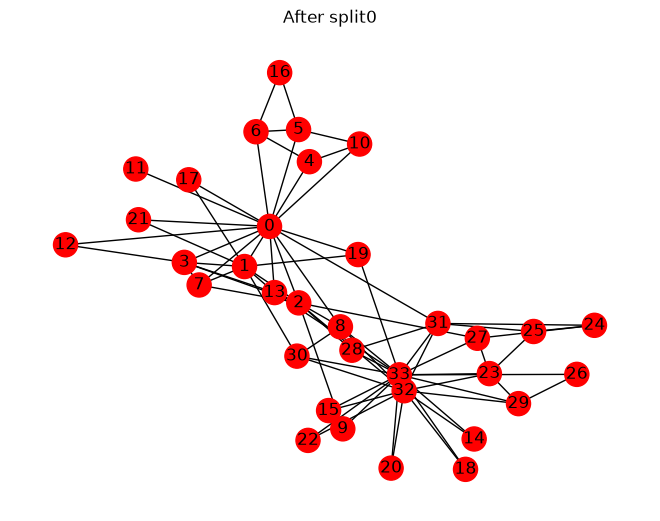

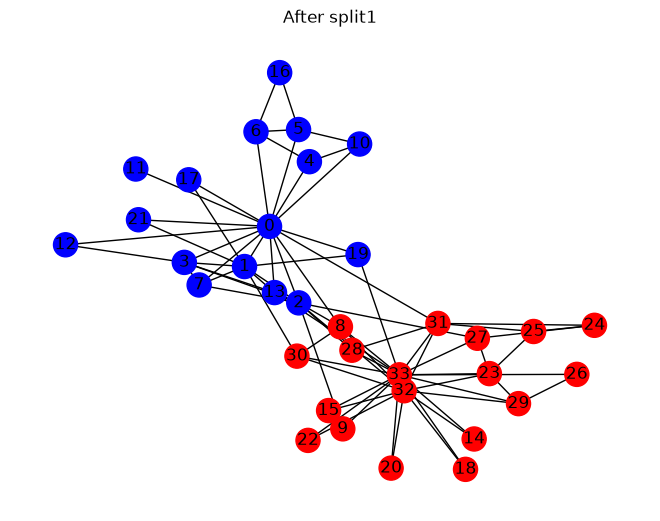

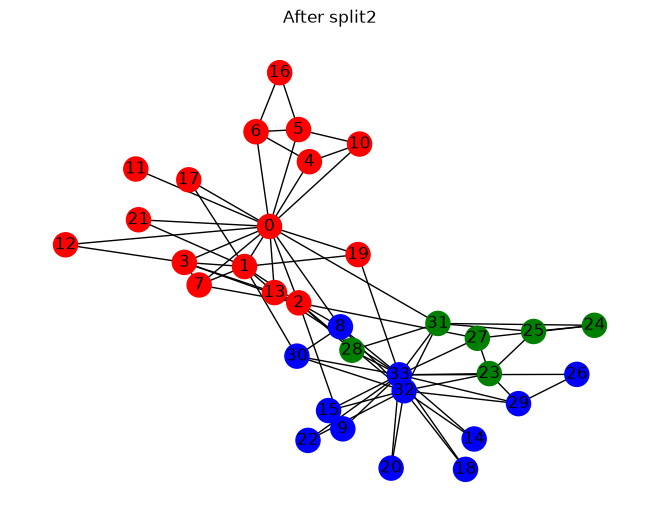

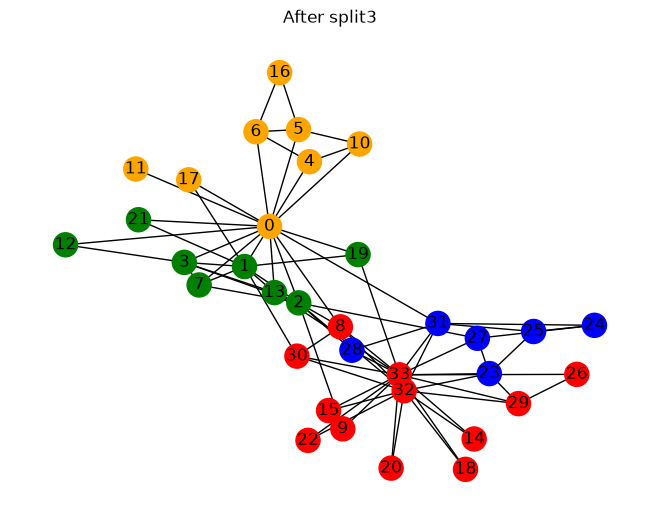

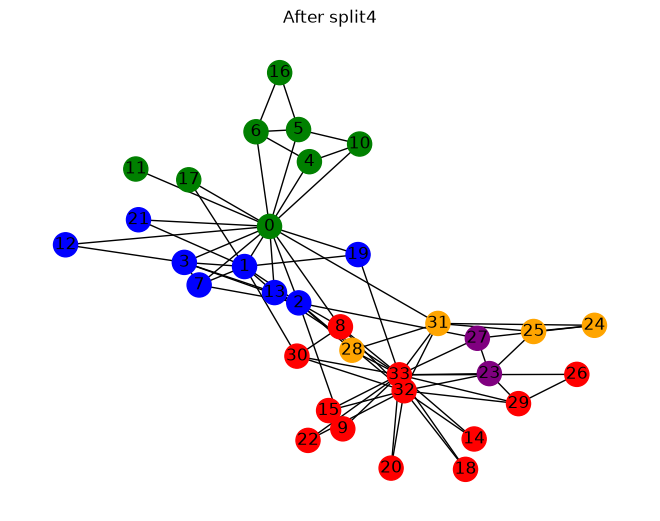

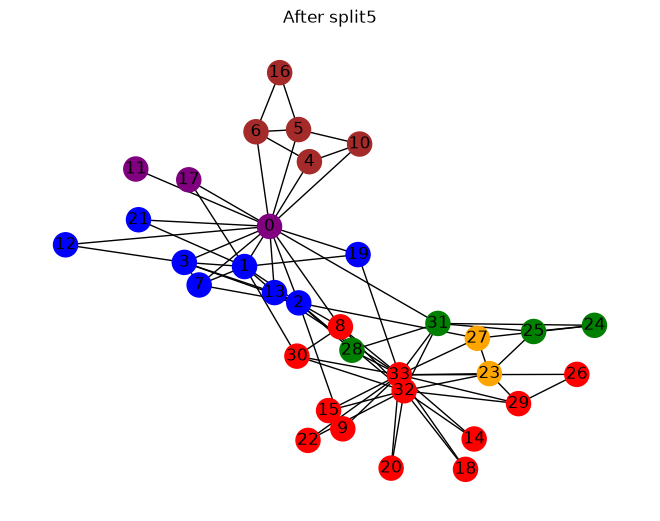

In [34]:
palette = ["red", "blue", "green", "orange", "purple", "brown", "pink", "gray",
           "cyan", "gold", "navy", "lime", "magenta", "teal", "maroon", "olive",
           "coral", "violet", "turquoise", "black"]

def draw_communities(groups, title):
    color_of = {}
    for c, group in enumerate(groups):
        for node in group:
            color_of[node] = palette[c%len(palette)]

    nx.draw(G, pos, with_labels=True, node_color=[color_of[n] for n in G.nodes()])
    plt.title(title)
    plt.show()

for step, groups in enumerate(history):
    draw_communities(groups, "After split" + str(step))

In [35]:
degree_list = []
for groups in history:
    d = {}
    for group in groups:
        sub = G.subgraph(group)
        d.update(nx.degree_centrality(sub))
    degree_list.append(d)

betweenness_list = []
for groups in history:
    d = {}
    for group in groups:
        sub = G.subgraph(group)
        d.update(nx.betweenness_centrality(sub))
    betweenness_list.append(d)

closeness_list = []
for groups in history:
    d = {}
    for group in groups:
        sub = G.subgraph(group)
        d.update(nx.closeness_centrality(sub))
    closeness_list.append(d)

clustering_list = []
for groups in history:
    d = {}
    for group in groups:
        sub = G.subgraph(group)
        d.update(nx.clustering(sub))
    clustering_list.append(d)



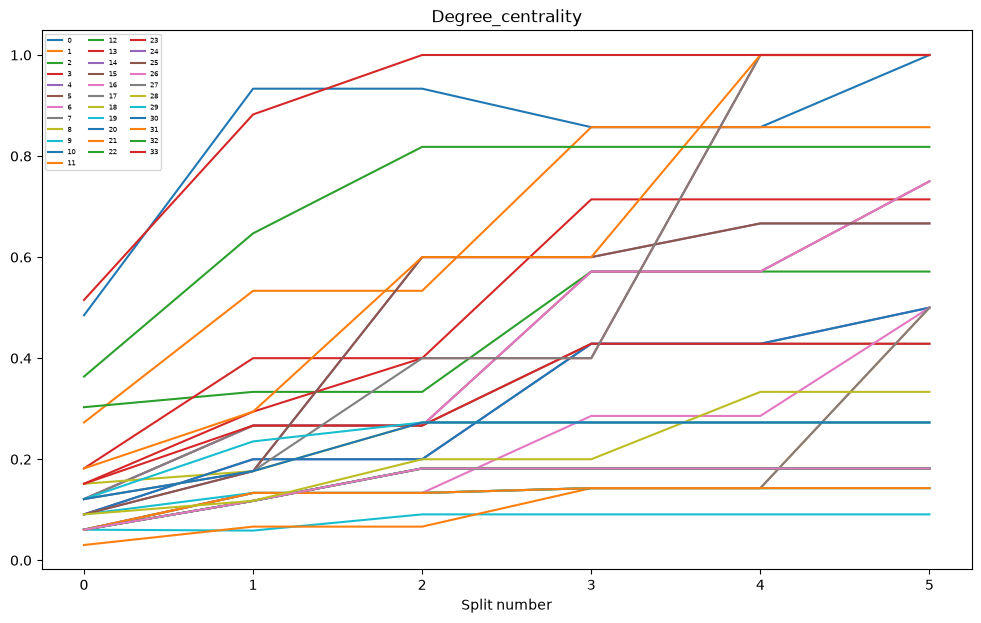

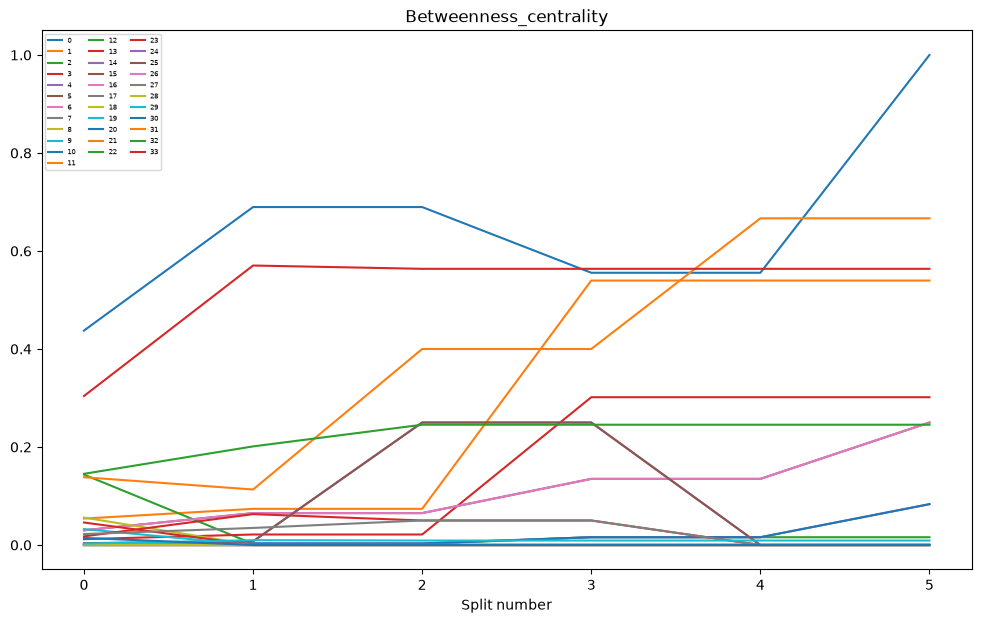

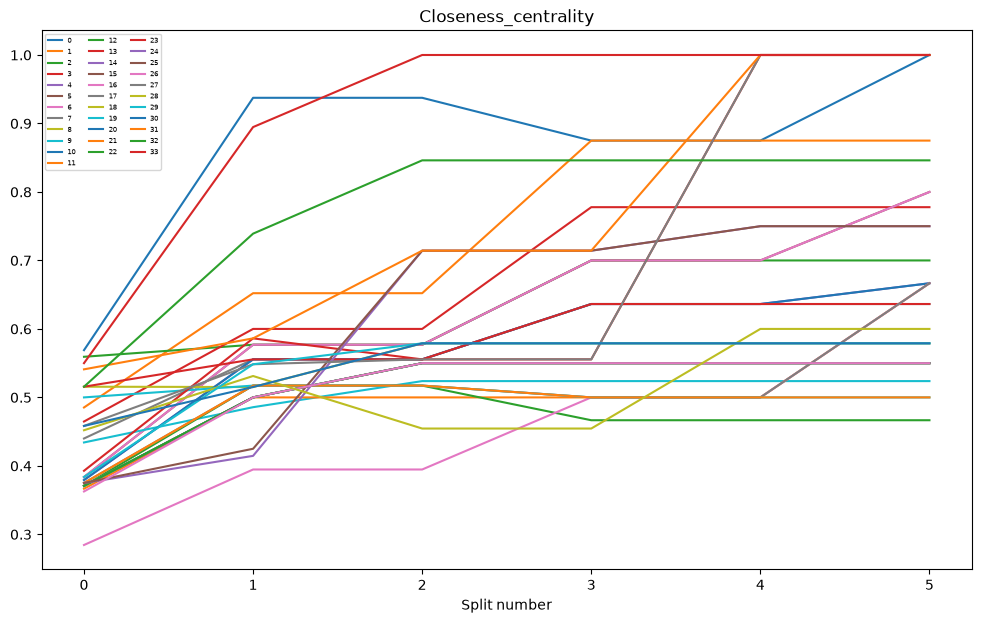

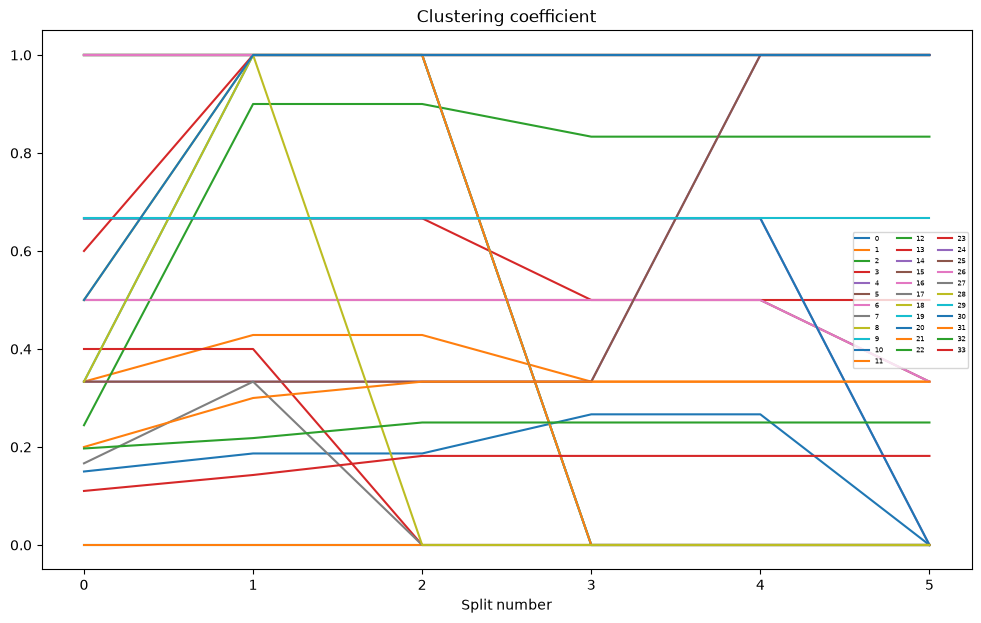

In [36]:
def plot_metric(metric_list, name):
    plt.figure(figsize = (12,7))
    for node in G.nodes():
        values = []
        for d in metric_list:
            values.append(d[node])
        plt.plot(values, label = str(node))
    plt.title(name)
    plt.xlabel("Split number")
    plt.legend(ncol = 3, fontsize = 5)
    plt.show()

plot_metric(degree_list, "Degree_centrality")
plot_metric(betweenness_list, "Betweenness_centrality")
plot_metric(closeness_list, "Closeness_centrality")
plot_metric(clustering_list, "Clustering coefficient")


Notes:

    - The initial graph has 34 nodes and 78 edges.
    - Method used is recursive spectral bisection on the    modularity matrix.
    - Tolerance used is 1e-8. Different tolerance can cause change in no. of splits.
    - Spring layout is fixed.(seed = 42)
    - Result: 12 splits and 13 communities.

Discussion: 

    - Nodes 0 and 33 consistently stay central accross splits. The degree-centrality and betweenness-centrality graphs show this clearly.
    - Measures are counted within each group, so measures change as groups change. Degree and closeness rise as groups shrink, since in a smaller hub, a node can be connected to a larger fraction of everyone.
    - Clustering meanwhile tends to 1 or 0 in small groups.
    - We split only those groups where the modularity change is positive after the split, this ensures groups don't get smaller and smaller.
    - Overall, the spectral method found the real split in the club using only friendship ties, with one member on the wrong side, and went on to divide it into 6 communities. The centrality measures changed with each split because they were computed inside each community, so a node’s importance depends on its group as well as its own connections. Nodes [0 and 33] stayed central throughout, which fits their role as the leaders of the two factions.
 